# Hello Again!

If you recall, in the [algorithms notebook](../05-algorithms.ipynb) I introduced the Quantum Approximate Optimization Algorithm (QAOA) through the regular unfrustrated Ising model, where all spins preferentially align in the same direction. Although this served as an excellent demonstration of the basic stuff, the resulting energy landscape was relatively simple.

Nature, however, is rarely so cooperative. Many systems like the Ising model(s) contain competing interactions exhibiting frustration, which naturally lead to tons of local minima all over the place. I'll help you explore how QAOA performs on a trifecta of such increasingly challenging *spin-glass Hamiltonians.* Beginning with a simple frustrated Ising-adjacent, I'll gradually introduce disorder before studying two of the most influential models in spin-glass physics: the Edwards-Anderson model and the Sherrington-Kirkpatrick model.

Also, this one is another huge notebook, so I recommend you read it in sections. The first section is a bit of a review of the Ising model, but the rest is all new material. If you want to skip the review, feel free to jump straight to later sections.

In [2]:
import numpy as np, matplotlib.pyplot as plt, networkx as nx, scipy.optimize
plt.style.use(['science', 'notebook', 'grid', 'dark_background'])
from time import time

# OTHER QISKIT IMPORTS

from qiskit import *
from qiskit.visualization import *
from qiskit.circuit.library import *
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit_aer import *
from qiskit.quantum_info import SparsePauliOp
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA, SPSA

# DRAW STYLE (default mpl dark), check https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits and 
# https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.circuit_drawer for more styles

def draw_circuit(qc):
    return qc.draw(output = 'mpl', style = 'iqp-dark')

What's a spin glass? They're basically Ising-adjacents plus a whole lot of built-in disorder in the interactions. Interspin interactions can be randomly assigned to be either (anti)ferromagnetic. This makes them an interesting testbed for optimization algorithms, like QAOA. Our goal here is not merely to apply QAOA for optimization, but to investigate it as a tool for studying many-body physics. Also, the term "glass" comes from an analogy between the magnetic disorder in a spin glass and the positional disorder of a conventional, chemical window glass. 

# Frustration:

Try drawing a triangle of spins and label each edge with an interaction strength $J_{ij}$. A triangular plaquette containing an **odd number of antiferromagnetic bonds** $(J_{ij}<0)$ is said to be *frustrated.* This is so because it's impossible to satisfy all three interactions simultaneously. By contrast, the fully ferromagnetic triangle is not frustrated because **all three** interactions can be minimized at once.

This should make intuitive sense even before introducing the mathematics. Try assigning the spin configuration $(\ket{\uparrow\downarrow\uparrow})$ to an antiferromagnetic triangle. Two of the three bonds are satisfied, but the third isn't. No matter how the spins are arranged, at least one interaction remains "unhappy". This inability to satisfy every one of these interactions simultaneously is the core idea of frustration.

Before proceeding, a brief note on notation is in order. In condensed matter physics, spin-half particles are often described using the spin operators $\hat{\cal S}_k$ where $k\,\in \{X,Y,Z\}$, which are built up as $\hat{\cal S}_k = (\hbar/2)\,\,\hat\sigma_k$. Since Qiskit and most quantum-computing libraries are built directly from Pauli operators, it's convenient to work with $(\hat\sigma_k)$ throughout this notebook.

The interaction Hamiltonian for a general Ising-like spin system is

$$\hat{\mathscr H}_i = -\sum_{\langle i,j\rangle}J_{ij}\,\hat\sigma_Z^{(i)} \hat\sigma_Z^{(j)}$$

where $J_{ij}$ is the *coupling* between spins $i,j$. Positive couplings are ferromagnetic and favor aligned spins, while negative couplings are antiferromagnetic and favor anti-aligned spins.

Consider the fully antiferromagnetic case on your triangle;

$$J_{01}=J_{12}=J_{20}=-1$$

The lowest-energy configurations have energy $-1$, for example $(\ket{\uparrow\downarrow\uparrow})$ and its symmetry-related equivalents. No configuration can achieve the "ideal" energy $-3$, because doing so would require all three bonds to be simultaneously satisfied, i.e. impossible on an antiferromagnetic triangle.

Unsurprisingly, your 'triangle Hamiltonian' is $$\hat{\mathscr H}_\text{tri} = \hat\sigma_Z^{(0)}\hat\sigma_Z^{(1)} + \hat\sigma_Z^{(1)}\hat\sigma_Z^{(2)} + \hat\sigma_Z^{(2)}\hat\sigma_Z^{(0)}$$

In [3]:
def triangle_hamiltonian(J_01, J_12, J_02):
    
    return SparsePauliOp.from_list([
        
        ("IZZ", -J_01), # Z0 Z1
        ("ZZI", -J_12), # Z1 Z2
        ("ZIZ", -J_02)  # Z2 Z0

    ])

H_tri = triangle_hamiltonian(
    
    J_01 = -1,
    J_12 = -1,
    J_02 = -1

)

print(H_tri)

SparsePauliOp(['IZZ', 'ZZI', 'ZIZ'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j])


Try the following coupling configurations:

1. (+1,+1,+1)
2. (-1,-1,-1)
3. (+1,+1,-1)
4. (+1,-1,-1)

For each case:
- Find the exact ground-state energy.
- Determine whether the system is frustrated.
- Compare the QAOA result to the exact solution.

In [4]:
eigenvalues = np.linalg.eigvalsh(H_tri.to_matrix())
print(eigenvalues)

[-1. -1. -1. -1. -1. -1.  3.  3.]


In [5]:
groundstate_energy = eigenvalues[0]
print(f"Ground state energy: {groundstate_energy}")

Ground state energy: -1.0


`QAOAAnsatz` is a class that constructs the QAOA ansatz circuit layers for a given cost operator, a neat feature to avoid having to manually construct the circuit like when I introduced QAOA in the [algorithms notebook](../05-algorithms.ipynb). The `reps` argument specifies the number of layers, which is equivalent to the $p$ parameter in the original QAOA paper.

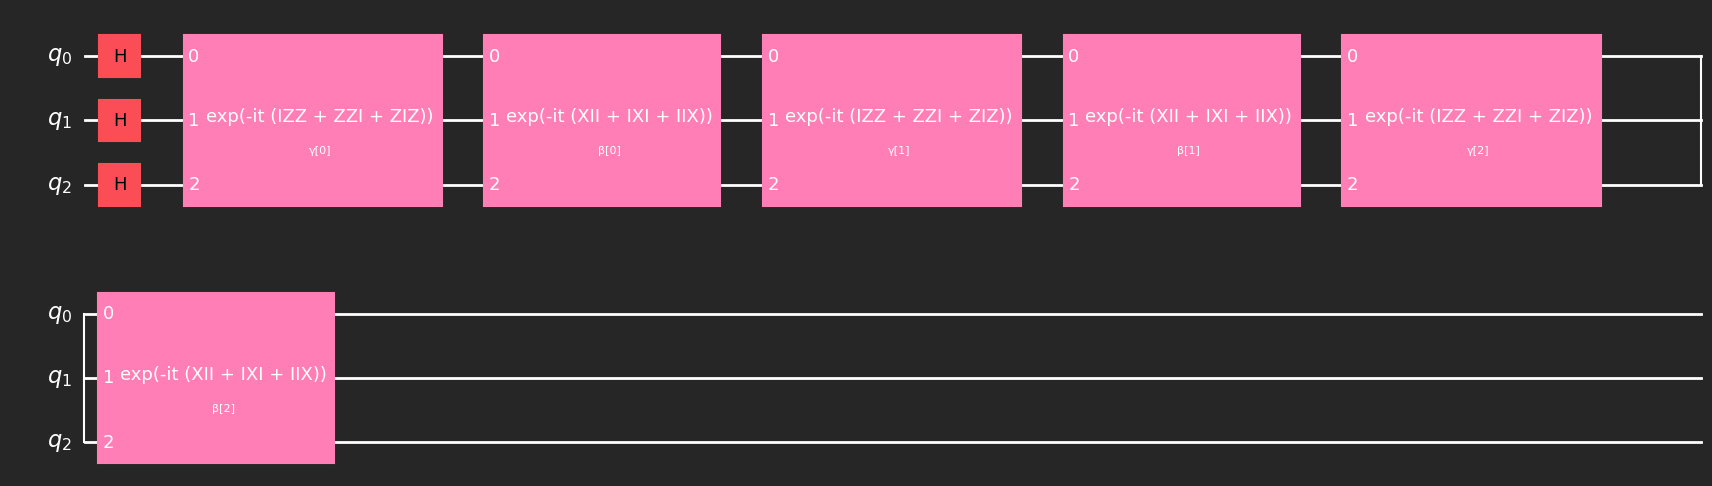

In [6]:
p = 3 # Set as desired or sufficient, I found that 4+ is overkill for this notebook

ansatz = QAOAAnsatz(

    cost_operator = H_tri,
    reps = p

)

draw_circuit(ansatz.decompose())

In [7]:
import warnings
from scipy.sparse import SparseEfficiencyWarning

warnings.filterwarnings(
    "ignore",
    category = SparseEfficiencyWarning
)

`QAOA` is another class that implements the algorithm layer itself, so no more manual construction and optimization loop! We can choose `COBYLA` for now, then compare with other optimizers later.

In [8]:
qaoa = QAOA(
    
    sampler = StatevectorSampler(),
    optimizer = COBYLA(maxiter = 1000),
    reps = p

)

In [9]:
result = qaoa.compute_minimum_eigenvalue(operator = H_tri)

print(

    f"QAOA returned eigenvalue {result.eigenvalue.real:.6f} "
    f"as compared to the exact eigenvalue {np.min(eigenvalues):.2f} "
    f"with an error of {np.abs(result.eigenvalue.real - np.min(eigenvalues)) / np.min(eigenvalues) * 100:.2f}%"

)

QAOA returned eigenvalue -0.992188 as compared to the exact eigenvalue -1.00 with an error of -0.78%


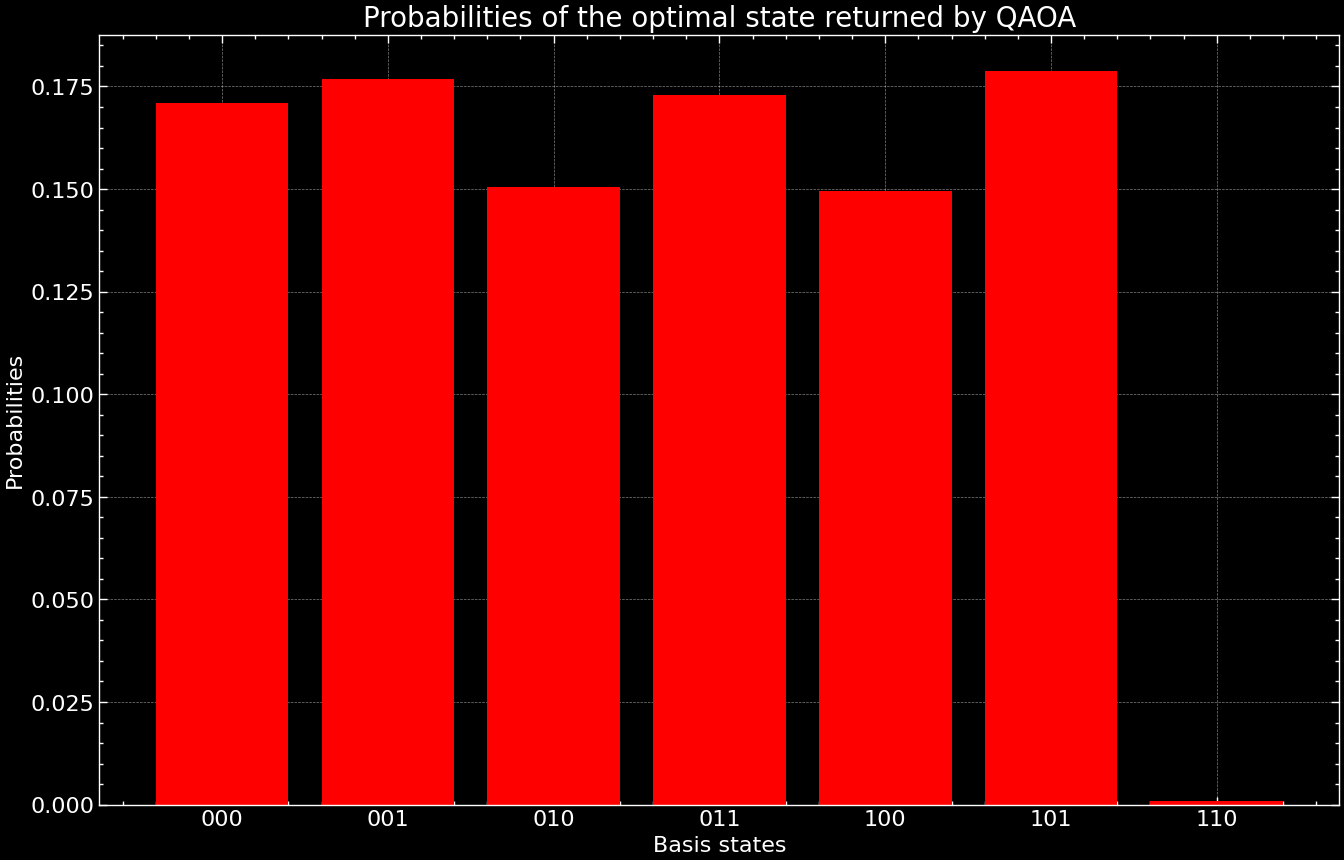

In [10]:
optimal_state = result.eigenstate
probabilities = np.array(list(optimal_state.values()))

plt.figure(figsize = (16, 10))
plt.bar(range(len(probabilities)), probabilities, color = 'red')

plt.title("Probabilities of the optimal state returned by QAOA", fontsize = 20)
plt.xlabel("Basis states", fontsize = 16)
plt.ylabel("Probabilities", fontsize = 16)

plt.xticks(range(len(probabilities)), [f"{i:03b}" for i in range(len(probabilities))], fontsize = 16)
plt.yticks(fontsize = 16)
plt.show()

From this, it should be clear that unlike the ferromagnetic Ising model, there is no unique configuration minimizing all interactions, but QAOA distributes most of its probability amplitude over the **lowest-energy** configurations.

You might recall from physics that in window glass or any amorphous solid, the atomic bond structure is highly irregular; in contrast, a crystal has a uniform pattern of atomic bonds. In ferromagnetic solids, magnetic spins all align in the same direction; this is analogous to a crystal's lattice-based structure. Spin glasses are frustrated because they contain many such polygons, or more generally, configurations of spins with competing interactions.

You'd wouldn't be wrong to come to the conclusion that spin glasses are, or at least feature *metastable* systems, because they're "stuck" in stable configurations other than the true ground-state configuration. Think of a ball rolling down a hill. If the ball is in a valley, it is stable. But if there are many valleys, the ball may be stuck in a local minimum and not reach the global minimum.

The triangle exhibits competing interations and frustration, though lacks the "quenched disorder" trope charachteristic of a traditional EA spin glass. But, there's still **only three** spins. To obtain a genuine spin glass, we must introduce disorder by allowing the couplings themselves to vary randomly throughout the lattice. This leads us to the logical leap to... 

# The Edwards-Anderson Model

The triangle you constructed remains a highly structured system containing — you guessed it — only three spins. To construct a genuine spin glass, we must introduce disorder by allowing the couplings themselves to vary throughout the lattice. One way to do just that is to assign each bond to be either ferromagnetic or antiferromagnetic randomly.

The Edwards–Anderson (which I'll abbreviate henceforth as EA) model is the canonical finite-dimensional spin-glass model. Spins occupy the sites of a regular lattice and interact only with their nearest neighbors, just as in the ordinary Ising model. What's different is that the couplings are not all identical, but each bond is assigned a random interaction strength.

The Hamiltonian is therefore

$$\hat{\mathscr H}_\text{EA} = -\sum_{\langle i,j\rangle} J_{ij}\,\hat\sigma_Z^{(i)} \hat\sigma_Z^{(j)}$$

which at first glance appears almost identical to the Ising Hamiltonian, but the crucial difference is that the couplings now vary from bond to bond, or simply put: $J_{ij}$ is a random variable quenched from a bimodal distribution $$P(J_{ij}) = \frac{1}{2}\delta(J_{ij}-1) + \frac{1}{2}\delta(J_{ij}+1)$$

Because of random coupling assignment, each realization of the EA model is unique, for lack of a better term. Some may be relatively easy to optimize, while others might be annoying, containing a large number of local minima separated by substantial energy barriers, which might make this piece of work a testbed for performance evaluation of hard optimization problems.

To make this comprehensible, let's use figures to illustrate the difference between a ferromagnetic Ising model and a spin glass. 

I can introduce you to `networkx`, which is a package for creating/visualizing graphs. Don't worry, you don't need to know much about it to use it here. I'll just make you a helper function to visualize the lattice. To start, you can plot our earlier spin triangle here:

In [11]:
G_tri = nx.Graph()
G_tri.add_nodes_from(range(3))

couplings_tri = {

    (0, 1): -1,
    (1, 2): -1,
    (0, 2): -1

}

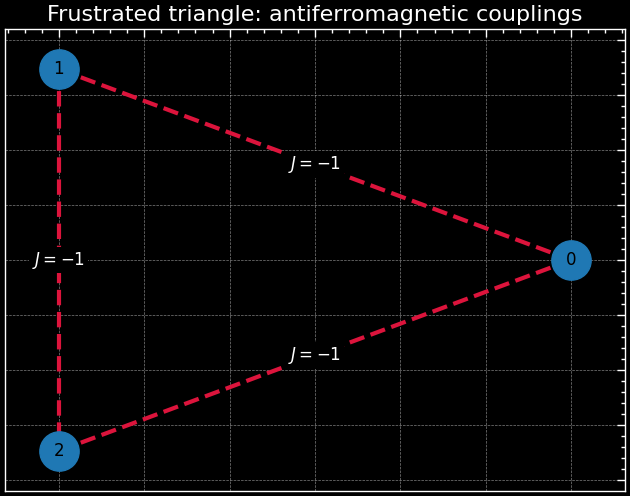

In [12]:
for (i, j), J in couplings_tri.items():

    G_tri.add_edge(i, j, coupling = J, color = "crimson" if J < 0 else "dodgerblue")

pos = nx.circular_layout(G_tri)

nx.draw_networkx_nodes(G_tri, pos, node_size = 800)
nx.draw_networkx_labels(G_tri, pos)

for (i, j), J in couplings_tri.items():

    nx.draw_networkx_edges(G_tri, pos, edgelist = [(i, j)], width = 3, style = "solid" if J == 1 else "dashed", edge_color = "crimson" if J < 0 else "dodgerblue")

    x = (pos[i][0] + pos[j][0]) / 2
    y = (pos[i][1] + pos[j][1]) / 2

    plt.text(x, y, f"$J={J:+d}$", fontsize = 12, ha = "center", va = "center", 
        bbox = dict(facecolor = "black", edgecolor = "none", pad = 2))

plt.title("Frustrated triangle: antiferromagnetic couplings");

Now for the EA model; construct a simple 1-D closed ring chain for demonstration, then we can move on to a 2-D lattice!

In [13]:
# Number of spins in the chain
n = 8

edges = [(i, (i + 1) % n) for i in range(n)]

# Random ±1 couplings
couplings = {

    edge: np.random.choice([-1, 1])
    for edge in edges

}

print("EA couplings:")
for edge, J in couplings.items():
    print(f"J_{edge} = {J}")

EA couplings:
J_(0, 1) = -1
J_(1, 2) = -1
J_(2, 3) = -1
J_(3, 4) = -1
J_(4, 5) = 1
J_(5, 6) = -1
J_(6, 7) = -1
J_(7, 0) = 1


In [14]:
def ea_hamiltonian(n, couplings):

    terms = []

    for (i, j), J in couplings.items():

        pauli = ["I"] * n
        pauli[i] = "Z"
        pauli[j] = "Z"

        terms.append(
            ("".join(pauli), -J)
        )

    return SparsePauliOp.from_list(terms)


H_EA = ea_hamiltonian(n, couplings)
print(H_EA)

SparsePauliOp(['ZZIIIIII', 'IZZIIIII', 'IIZZIIII', 'IIIZZIII', 'IIIIZZII', 'IIIIIZZI', 'IIIIIIZZ', 'ZIIIIIIZ'],
              coeffs=[ 1.+0.j,  1.+0.j,  1.+0.j,  1.+0.j, -1.+0.j,  1.+0.j,  1.+0.j, -1.+0.j])


The couplings allow us to now plot the chain with the edges colored according to their interaction strength. Try to recognize the coupling strengths on each edge!

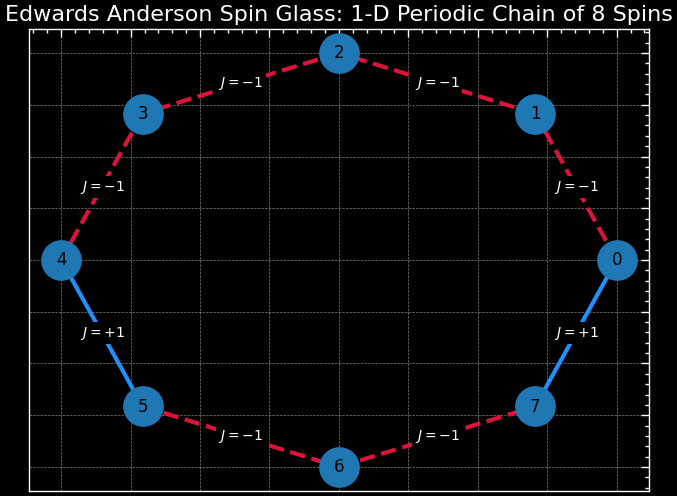

In [15]:
G_EA = nx.Graph()
G_EA.add_nodes_from(range(n))

for (i, j), J in couplings.items():

    G_EA.add_edge(i, j, coupling = J, color = "crimson" if J < 0 else "dodgerblue")

pos = nx.circular_layout(G_EA)
nx.draw_networkx_nodes(G_EA, pos, node_size = 800)
nx.draw_networkx_labels(G_EA, pos)

for (i, j), J in couplings.items():

    nx.draw_networkx_edges(G_EA, pos, edgelist = [(i, j)], width = 3, style = "solid" if J == 1 else "dashed", edge_color = "crimson" if J < 0 else "dodgerblue"
)

    x = (pos[i][0] + pos[j][0]) / 2
    y = (pos[i][1] + pos[j][1]) / 2

    plt.text(x, y, f"$J={J:+d}$", fontsize = 10, ha = "center", va = "center",
            bbox = dict(facecolor = "black", edgecolor = "none", pad = 2))

#plt.axis("equal") # Uncomment this line to make the graph circular instead of elliptical
plt.title(f"Edwards Anderson Spin Glass: 1-D Periodic Chain of {n} Spins");

Extracting the exact ground state energy and corresponding bitstrings:

In [16]:
eigenvalues, eigenvectors = np.linalg.eigh(H_EA.to_matrix())
exact_ground_energy_EA = eigenvalues[0]
ground_states_EA = []

for i, E in enumerate(eigenvalues):

    if np.isclose(E, exact_ground_energy_EA):

        bitstring = format(i, f"0{n}b")
        ground_states_EA.append(bitstring)

print("Exact ground energy:", exact_ground_energy_EA)
print("Ground states:", ground_states_EA)

Exact ground energy: -8.0
Ground states: ['00000000', '00000001']


There is a chance that the ground state is either degenerate or it hits the theoretical minimum, as we are considering random couplings with relatively small `n`. In this case, just rerun from the definition of `couplings` to generate a fresh random instance of your chain.

The following will take a while, especially at high iterations and depth. Try changing `p` or `maxiter` if convergence fails to a reasonable degree of estimation.

In [17]:
p = 3 # Set a nice balance between accuracy and speed for this notebook, I'd say 5+ is overkill for 8+ qubits.

qaoa = QAOA(

    sampler = StatevectorSampler(default_shots = 2 ** 14),
    optimizer = COBYLA(maxiter = 1000), 
    reps = p

)

In [18]:
start_time = time()
result_EA = qaoa.compute_minimum_eigenvalue(operator = H_EA)
elapsed_time = time() - start_time

print(

    f"QAOA returned eigenvalue {result_EA.eigenvalue.real:.6f} "
    f"as compared to the exact eigenvalue {exact_ground_energy_EA:.6f} "
    f"with error of {np.abs(result_EA.eigenvalue.real - exact_ground_energy_EA) / np.abs(exact_ground_energy_EA) * 100:.2f}% "
    f"in {elapsed_time:.2f} seconds"

)

QAOA returned eigenvalue -5.607178 as compared to the exact eigenvalue -8.000000 with error of 29.91% in 67.69 seconds


As the QAOA depth $p$ increases, the number of variational parameters plus circuit operations increases, making each optimization incrementally expensive. Since our objective here is of course, to study convergence rather than push uselessly deep circuits, we'll keep $p$ fixed and instead investigate the effect of the classical optimizer's iteration budget `maxiter` on accuracy and computational cost.

Also keep in mind that `COBYLA` and other optimizers favor convex optimization landscapes, so don't be surprised if increasing `maxiter` decreases your error, or decreases it linearly. QAOA in effect and pracice in rudimentary experiments like these exposes its nature as a local optimizer, and the optimizer's performance is highly dependent on the landscape of the cost function. Learning experience!

In [19]:
maxiters = [500, 750, 1000, 1250, 1500]
p = 3 

energies_EA = []
errors_EA = []
times_EA = []

for maxiter in maxiters:

    print(f"Running maxiter = {maxiter}...")
    optimizer = COBYLA(maxiter = maxiter)

    qaoa = QAOA(

        sampler = StatevectorSampler(default_shots = 2 ** 14),
        optimizer = optimizer,
        reps = p

    )

    start_time = time()
    result_EA = qaoa.compute_minimum_eigenvalue(operator = H_EA)
    elapsed = time() - start_time

    energies_EA.append(result_EA.eigenvalue.real)
    errors_EA.append(np.abs((result_EA.eigenvalue.real - exact_ground_energy_EA) / exact_ground_energy_EA) * 100)
    times_EA.append(elapsed)

    print(

        f"QAOA returned eigenvalue {result_EA.eigenvalue.real:.6f} "
        f"as compared to the exact eigenvalue {exact_ground_energy_EA:.6f} "
        f"with error of {np.abs(result_EA.eigenvalue.real - exact_ground_energy_EA) / np.abs(exact_ground_energy_EA) * 100:.2f}% "
        f"in {elapsed:.2f} seconds \n"

    )

Running maxiter = 500...
QAOA returned eigenvalue -5.656494 as compared to the exact eigenvalue -8.000000 with error of 29.29% in 84.88 seconds 

Running maxiter = 750...
QAOA returned eigenvalue -5.550049 as compared to the exact eigenvalue -8.000000 with error of 30.62% in 87.36 seconds 

Running maxiter = 1000...
QAOA returned eigenvalue -4.727539 as compared to the exact eigenvalue -8.000000 with error of 40.91% in 75.27 seconds 

Running maxiter = 1250...
QAOA returned eigenvalue -5.094482 as compared to the exact eigenvalue -8.000000 with error of 36.32% in 88.74 seconds 

Running maxiter = 1500...
QAOA returned eigenvalue -4.713623 as compared to the exact eigenvalue -8.000000 with error of 41.08% in 80.98 seconds 



The errorbar is $N_\text{opt.}=\text{min}\{N:\epsilon(N)<\epsilon_\text{target}\%\}$ where you can set $\epsilon_\text{target}$ as desired, maybe $1\%$ if we're really pushing for accuracy (remember to inflate the depth to 6+ if you wish to achieve this). 

In [20]:
threshold = 0.5 # in percent
valid = np.where(np.array(errors_EA) < threshold)[0]

if len(valid) > 0:

    maxiter_opt = maxiters[valid[0]]
    print(f"Optimal maxiter = {maxiter_opt} achieved <{threshold}% error.")

else:

    maxiter_opt = None
    print(f"No tested maxiter achieved <{threshold}% error.")

No tested maxiter achieved <0.5% error.


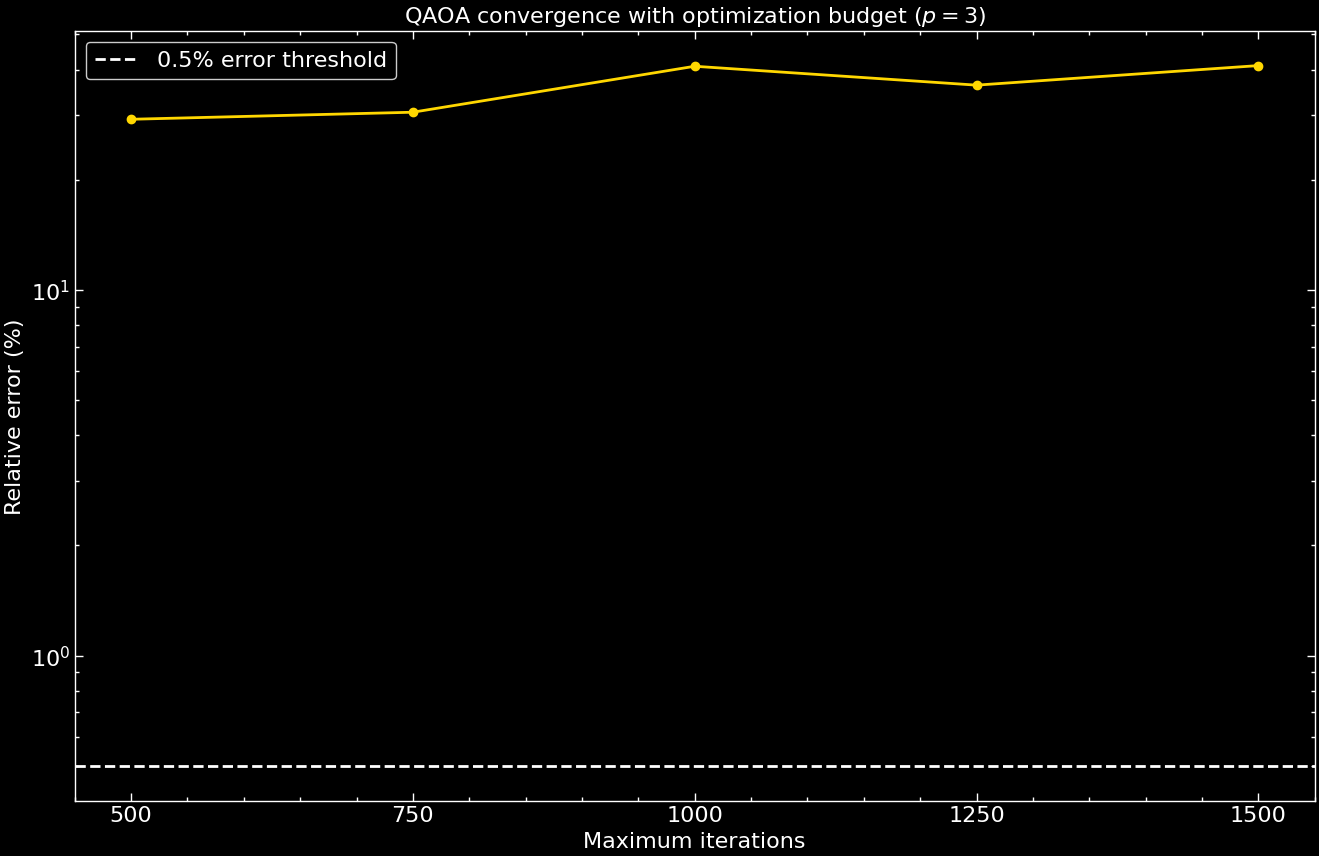

In [21]:
plt.figure(figsize = (16, 10))
plt.plot(maxiters, errors_EA, marker = "o", color = 'gold')
plt.axhline(threshold, linestyle = "--", label = f"{threshold}% error threshold")
plt.xticks(maxiters)
plt.yscale("log")

plt.xlabel("Maximum iterations")
plt.ylabel("Relative error (%)")
plt.title(f"QAOA convergence with optimization budget ($p={p}$)")
plt.legend()
plt.grid()

Generally, the errorbar should also be respectful of computational cost, so this might help:

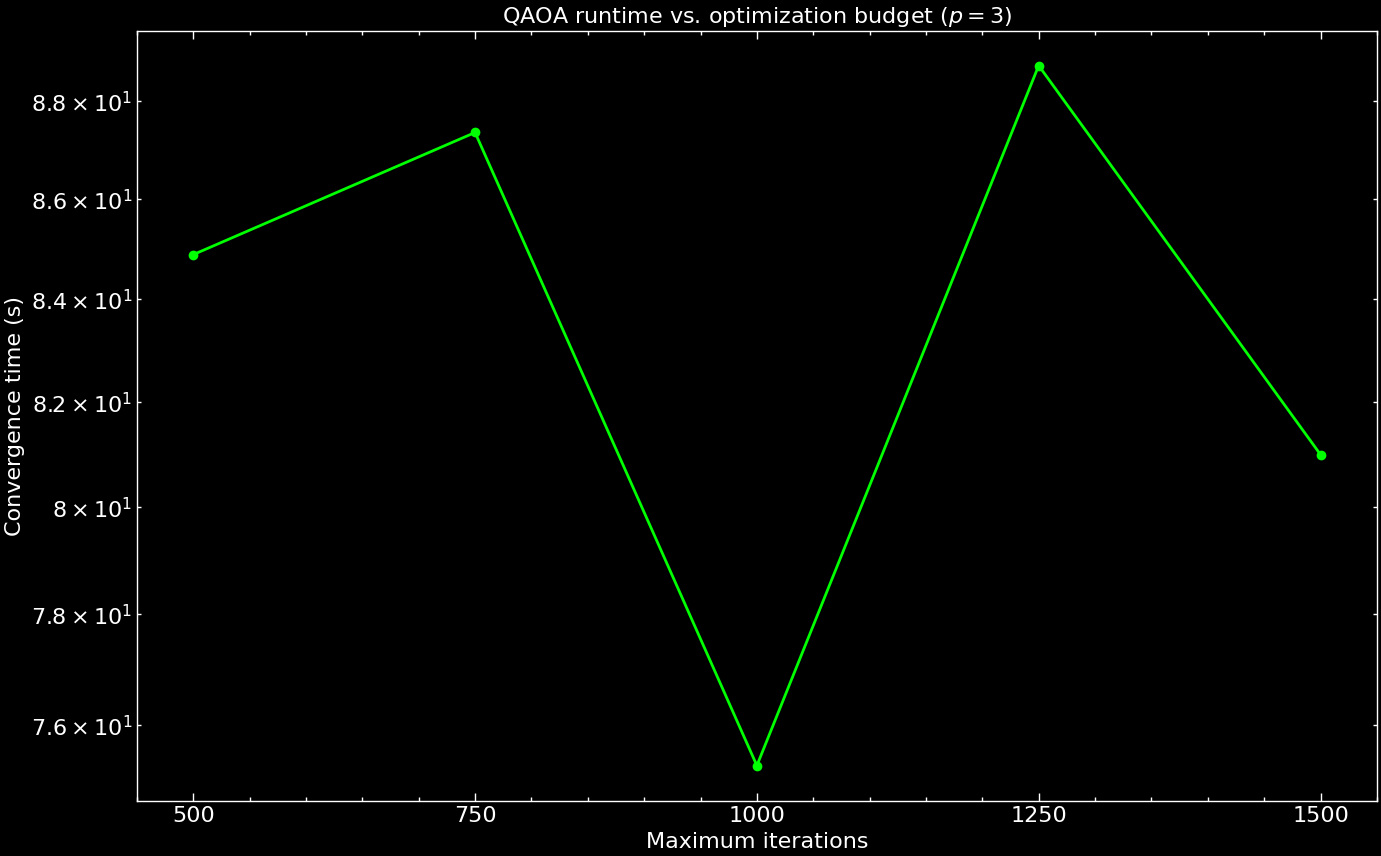

In [22]:
plt.figure(figsize = (16, 10))
plt.plot(maxiters, times_EA, marker = "o", color = 'lime')
plt.xticks(maxiters)
plt.yscale("log")

plt.xlabel("Maximum iterations")
plt.ylabel("Convergence time (s)")
plt.title(f"QAOA runtime vs. optimization budget ($p={p}$)")
plt.grid()

The EA model introduced the essential ingredient missing from the frustrated triangle, which is the quenched disorder in the interactions. Even our small instance of a periodic 1D chain would be considerably more difficult for QAOA to navigate. We now take the idea of random couplings one step further. What happens if we remove the restriction to nearest-neighbour interactions entirely?

# The Sherrington-Kirkpatrick Model

An exactly solvable model of a spin glass was introduced by David Sherrington and Scott Kirkpatrick in 1975. Adding to the list of creative names, the Sherrington–Kirkpatrick (SK) model is an Ising model with long-range, randomly distributed ferromagnetic and antiferromagnetic couplings. It provides a mean-field description of spin-glass behaviour, including the emergence of a complex, non-ergodic equilibrium state associated with replica symmetry breaking.

Unlike the EA model, interactions in the SK model are not restricted to neighbouring sites. Every pair of spins can interact, with the coupling strength drawn independently from a random distribution. In the standard SK model, these couplings are Gaussian distributed around 0 with variance 1.

The SK Hamiltonian is therefore $$\hat{\mathscr H}_\text{SK} = -\frac 1{\sqrt N}\sum_{i<j} J_{ij}\,\hat\sigma_Z^{(i)} \hat\sigma_Z^{(j)}$$ where $N$ is the number of spins. The $1/\sqrt N$ factor provides the conventional system-size normalization, keeping the energy per spin well behaved as $N\to\infty$, called the *thermodynamic limit*. For the small finite systems considered here, it is still useful to retain this factor so that our implementation corresponds directly to the standard SK model.

For an $N$-spin SK model, every pair interacts, so the interaction graph is the complete graph $K_N$.

In [23]:
rng = np.random.default_rng(42) # A fresh random realization is generated each time the cell is run.
couplings_SK = {}

n = 7          # I'd suggest <7, as SK is considerably more expensive than EA.

for i in range(n):

    for j in range(i + 1, n):

        couplings_SK[(i, j)] = rng.normal()

Unlike EA, these aren't restricted to $\mp 1$. You'll get values such as $J_{01}=0.43$, $J_{03}=-1.17$, etc.

In [24]:
G_SK = nx.Graph()
G_SK.add_nodes_from(range(n))

for (i, j), J in couplings_SK.items():

    G_SK.add_edge(i, j, coupling = J)

pos = nx.circular_layout(G_SK)

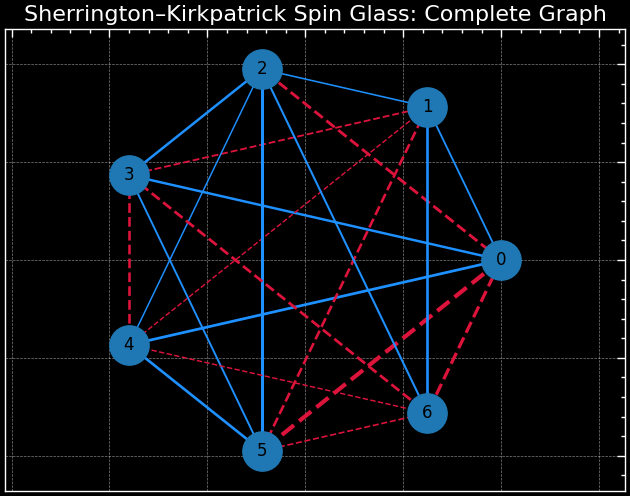

In [25]:
for (i, j), J in couplings_SK.items():

    nx.draw_networkx_edges(G_SK, pos, edgelist = [(i, j)], width = 1 + 2 * abs(J) / max(abs(x) for x in couplings_SK.values()), edge_color = "crimson" if J < 0 else "dodgerblue",
                        style = "dashed" if J < 0 else "solid")

nx.draw_networkx_nodes(G_SK, pos, node_size = 800)
nx.draw_networkx_labels(G_SK, pos)

plt.axis("equal")
plt.title("Sherrington–Kirkpatrick Spin Glass: Complete Graph")
plt.show()

I'd say that's for starters, a much more beautiful graph than EA :) A thicker edge implies a larger $J_{ij}$, and all other formatting rules apply from earlier.

In [26]:
H_SK = 0

for (i, j), J in couplings_SK.items():

    pauli = ["I"] * n
    pauli[n - 1 - i] = "Z"
    pauli[n - 1 - j] = "Z"

    H_SK += (-J / np.sqrt(n)) * SparsePauliOp.from_list([("".join(pauli), 1.0)])

print(H_SK)

SparsePauliOp(['IIIIIZZ', 'IIIIZIZ', 'IIIZIIZ', 'IIZIIIZ', 'IZIIIIZ', 'ZIIIIIZ', 'IIIIZZI', 'IIIZIZI', 'IIZIIZI', 'IZIIIZI', 'ZIIIIZI', 'IIIZZII', 'IIZIZII', 'IZIIZII', 'ZIIIZII', 'IIZZIII', 'IZIZIII', 'ZIIZIII', 'IZZIIII', 'ZIZIIII', 'ZZIIIII'],
              coeffs=[-0.11517223+0.j,  0.39307704+0.j, -0.28364389+0.j, -0.35550005+0.j,
  0.73742199+0.j,  0.49217759+0.j, -0.04831913+0.j,  0.11952846+0.j,
  0.00635024+0.j,  0.3224203 +0.j, -0.33238119+0.j, -0.29397772+0.j,
 -0.02495726+0.j, -0.42605713+0.j, -0.17670192+0.j,  0.32478202+0.j,
 -0.1393747 +0.j,  0.36242356+0.j, -0.33202301+0.j,  0.01887022+0.j,
  0.06987141+0.j])


In [27]:
print(f"For {n} spins: ")
print(f"Number of interaction terms: {len(couplings_SK)}, with expected interaction terms: {n * (n - 1) // 2}")

For 7 spins: 
Number of interaction terms: 21, with expected interaction terms: 21


In [28]:
eigenvalues, eigenvectors = np.linalg.eigh(H_SK.to_matrix())
exact_ground_energy_SK = eigenvalues[0]
ground_states_SK = []

for i, E in enumerate(eigenvalues):

    if np.isclose(E, exact_ground_energy_SK):

        bitstring = format(i, f"0{n}b")
        ground_states_SK.append(bitstring)

print("Exact ground energy:", exact_ground_energy_SK)
print("Ground states:", ground_states_SK)

Exact ground energy: -2.731957336369122
Ground states: ['0000000', '0000001']


We'll do an optimal `maxiter` run again, but let's just choose 1000 for now.

In [29]:
ansatz = QAOAAnsatz(
    cost_operator = H_SK,
    reps = 6
)

print(ansatz.num_parameters)

12


In [30]:
p = 6

qaoa = QAOA(

    sampler = StatevectorSampler(default_shots = 2 ** 14),
    optimizer = COBYLA(maxiter = 1000), 
    reps = p

)

In [31]:
start_time = time()
result_SK = qaoa.compute_minimum_eigenvalue(operator = H_SK)
elapsed_time = time() - start_time

print(

    f"QAOA returned eigenvalue {result_SK.eigenvalue.real:.6f} "
    f"as compared to the exact eigenvalue {exact_ground_energy_SK:.6f} "
    f"with error of {np.abs(result_SK.eigenvalue.real - exact_ground_energy_SK) / np.abs(exact_ground_energy_SK) * 100:.2f}% "
    f"in {elapsed_time:.2f} seconds"

)

QAOA returned eigenvalue -0.364123 as compared to the exact eigenvalue -2.731957 with error of 86.67% in 73.35 seconds


Not the best, huh? I tried using different optimizers and reducing the depth, unfortunately to similar or even worse errors with SK specifically. I'd recommend just dropping QAOA because SK is sufficiently structured as an ensemble that generic instance-by-instance optimization isn't necessarily the best way to approach it. You could say that this exposes QAOA's limitation when considering a model like the SK model, judging by the fact that regardless of the extent of classical optimization (governed by `maxiter` and depth `p`) doesn't produce any remarkable change in error whatsoever.

The Sherrington–Kirkpatrick model therefore represents the most general of the **classical** spin-glass systems considered here. Starting from the frustrated triangle, we introduced disorder while retaining local interactions in the Edwards–Anderson model, and finally removed the restriction to nearest neighbors in the SK model, allowing every spin to interact with every other spin. Despite their differences, all three models' Hamiltonians are diagonal in the computational basis.

So far, however, there's been something rather conspicuous missing from our spin models: quantum dynamics. Although we've been using quantum circuits to solve these problems, the spin-glass Hamiltonians themselves have remained classical in character. Every term has been composed of $\hat\sigma_Z$ operators, and consequently all terms commute with one another. A computational-basis state therefore remains an eigenstate of the Hamiltonian, and the problem ultimately reduces to finding the lowest-energy classical spin configuration. This is therefore a beautiful transition into...

# Transverse-Field Models:

To introduce genuinely quantum behaviour, you can add a transverse magnetic field. This produces the once-again, creatively named *Transverse-Field Ising Model* (TFIM), in which the spins are subject not only to their interactions along the $\hat z$-direction, but also to a field along the $\hat x$ direction. The resulting $\hat\sigma_X$ terms do not commute with the $\hat\sigma_Z$ terms, allowing quantum fluctuations between different spin configurations.

The generalized Hamiltonian is $$\hat{\mathscr H}_\text{tfim}=-\sum_{\langle i,j\rangle}J_{ij}\,\hat\sigma_Z^{(i)} \hat\sigma_Z^{(j)}-h\sum_i\hat\sigma_X^{(i)}$$ The familiar first term favours alignment between neighbouring spins, while the second introduces quantum fluctuations that compete with this ordering, by virtue of the magnetic field of strength $h$, making the transition from a regime dominated by spin-spin interactions to one dominated by quantum fluctuations. This is the point where our discussion moves from using quantum computers to solve classical spin-glass problems toward studying a system whose Hamiltonian itself is intrinsically quantum.

Also, because quantum fluctuations are now an intrinsic part of the model, I thought that TFIM would be a perfectly natural candidate for taking our calculations beyond simulation. A classical computer can still exactly diagonalize the small systems considered here, but a QPU would provide that platform on which the noncommutations of the Hamiltonian can actually be manipulated well. Of course, this is where the imperfections of current quantum hardware would surface. 

# Important: QPU Usage Quotas Guide

Let me demonstrate a small $a\times b$ (2-d for a change!) lattice this time to savor the limited time we get on QPUs. Here's a neat visualizer:

In [3]:
a = 4
b = 2
n = a * b

tfim_edges = []

for i in range(a):

    for j in range(b):

        # Horizontal neighbor
        if j < b - 1:

            tfim_edges.append((i * b + j, i * b + j + 1))

        # Vertical neighbor
        if i < a - 1:

            tfim_edges.append((i * b + j, (i + 1) * b + j))

print(f"Number of spins: {n}")
print(f"Number of bonds: {len(tfim_edges)}")
print("Edges:", tfim_edges)

Number of spins: 8
Number of bonds: 10
Edges: [(0, 1), (0, 2), (1, 3), (2, 3), (2, 4), (3, 5), (4, 5), (4, 6), (5, 7), (6, 7)]


In [4]:
rng = np.random.default_rng(42)

couplings_TFIM = {edge: rng.choice([-1, 1]) for edge in tfim_edges}

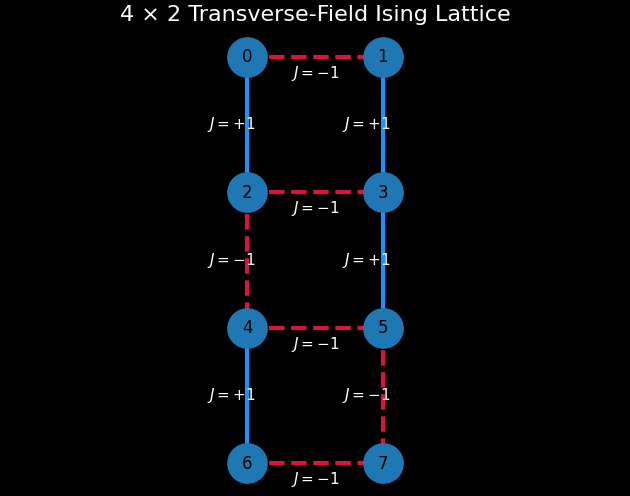

In [5]:
G_TFIM = nx.Graph()
G_TFIM.add_nodes_from(range(n))

for (i, j), J in couplings_TFIM.items():

    G_TFIM.add_edge(i, j, coupling = J)

pos = {i * b + j: (j, a - 1 - i) for i in range(a) for j in range(b)}

nx.draw_networkx_nodes(G_TFIM, pos, node_size = 800)
nx.draw_networkx_labels(G_TFIM, pos, font_size = 12)

for (i, j), J in couplings_TFIM.items():

    nx.draw_networkx_edges(G_TFIM, pos, edgelist=[(i, j)], width = 3, edge_color="crimson" if J < 0 else "dodgerblue", style="dashed" if J < 0 else "solid")

    x = (pos[i][0] + pos[j][0]) / 2
    y = (pos[i][1] + pos[j][1]) / 2

    dx = pos[j][1] - pos[i][1]
    dy = -(pos[j][0] - pos[i][0])

    norm = (dx ** 2 + dy ** 2) ** 0.5

    if norm != 0:

        dx /= norm
        dy /= norm

    plt.text(x + 0.12 * dx, y + 0.12 * dy, f"$J={J:+d}$", fontsize = 11, ha = "center", va = "center")

plt.axis("equal")
plt.axis("off")
plt.title(f"{a} × {b} Transverse-Field Ising Lattice")
plt.show()

There we are. Let's now construct the TFIM Hamiltonian for this lattice. The first term is the same as for EA, called the *cost Hamiltonian*, but except that I have to add the transverse field term, called the *mixer Hamiltonian*, which is simply a sum of $\hat\sigma_X$ operators acting on each spin.

In [6]:
def tfim_cost_hamiltonian(n, couplings, h):
    terms = []

    # ZZ interaction terms
    for (i, j), J in couplings.items():

        pauli = ["I"] * n
        pauli[i] = "Z"
        pauli[j] = "Z"

        terms.append(
            ("".join(pauli), -J)
        )

    return SparsePauliOp.from_list(terms)

def tfim_mixer_hamiltonian(n, h):

    terms = []

    # Transverse-field terms
    for i in range(n):

        pauli = ["I"] * n
        pauli[i] = "X"

        terms.append(
            ("".join(pauli), -h)
        )

    return SparsePauliOp.from_list(terms)

In [7]:
H_TFIM = tfim_cost_hamiltonian(n, couplings_TFIM, h = 1) + tfim_mixer_hamiltonian(n, h = 1)
print(H_TFIM)

SparsePauliOp(['ZZIIIIII', 'ZIZIIIII', 'IZIZIIII', 'IIZZIIII', 'IIZIZIII', 'IIIZIZII', 'IIIIZZII', 'IIIIZIZI', 'IIIIIZIZ', 'IIIIIIZZ', 'XIIIIIII', 'IXIIIIII', 'IIXIIIII', 'IIIXIIII', 'IIIIXIII', 'IIIIIXII', 'IIIIIIXI', 'IIIIIIIX'],
              coeffs=[ 1.+0.j, -1.+0.j, -1.+0.j,  1.+0.j,  1.+0.j, -1.+0.j,  1.+0.j, -1.+0.j,
  1.+0.j,  1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j,
 -1.+0.j, -1.+0.j])


In [8]:
print(f"For {H_TFIM.num_qubits} qubits:")
print(f"Number of Pauli terms: {len(H_TFIM)}")

For 8 qubits:
Number of Pauli terms: 18


In [9]:
eigenvalues, eigenvectors = np.linalg.eigh(H_TFIM.to_matrix())
exact_ground_energy_TFIM = eigenvalues[0]
ground_states_TFIM = []

for i, E in enumerate(eigenvalues):

    if np.isclose(E, exact_ground_energy_TFIM):

        bitstring = format(i, f"0{n}b")
        ground_states_TFIM.append(bitstring)

print("Exact ground energy:", exact_ground_energy_TFIM)
print("Ground states:", ground_states_TFIM)

Exact ground energy: -10.549674650307507
Ground states: ['00000000']


There's something important to note here. The TFIM Hamiltonian is no longer diagonal in the computational basis, as $[\hat\sigma_Z^{(i)}\hat\sigma_Z^{(j)},\hat\sigma_X^{(k)}]\neq 0$ for $i,j,k\in\{0,1,\ldots,n-1\}$. which essentially means that the ground state is a **superposition** of many many configurations of the computational basis. 

Let's see for ousrselves; I'll plot a barchart of probabilities of the computational basis states in the ground state of the TFIM Hamiltonian for you, and provide you with a sensible numerical limiter of representations as a fraction of the Hilbert statespace: $$n_\text{max.}=\text{min}(\text{max}(10, \lfloor 2^n/  20\rfloor), 30)$$ which entails
1. Always show at least 10 states,
2. Show roughly the top 5% of the Hilbert space, and
3. Never show more than 30 states.

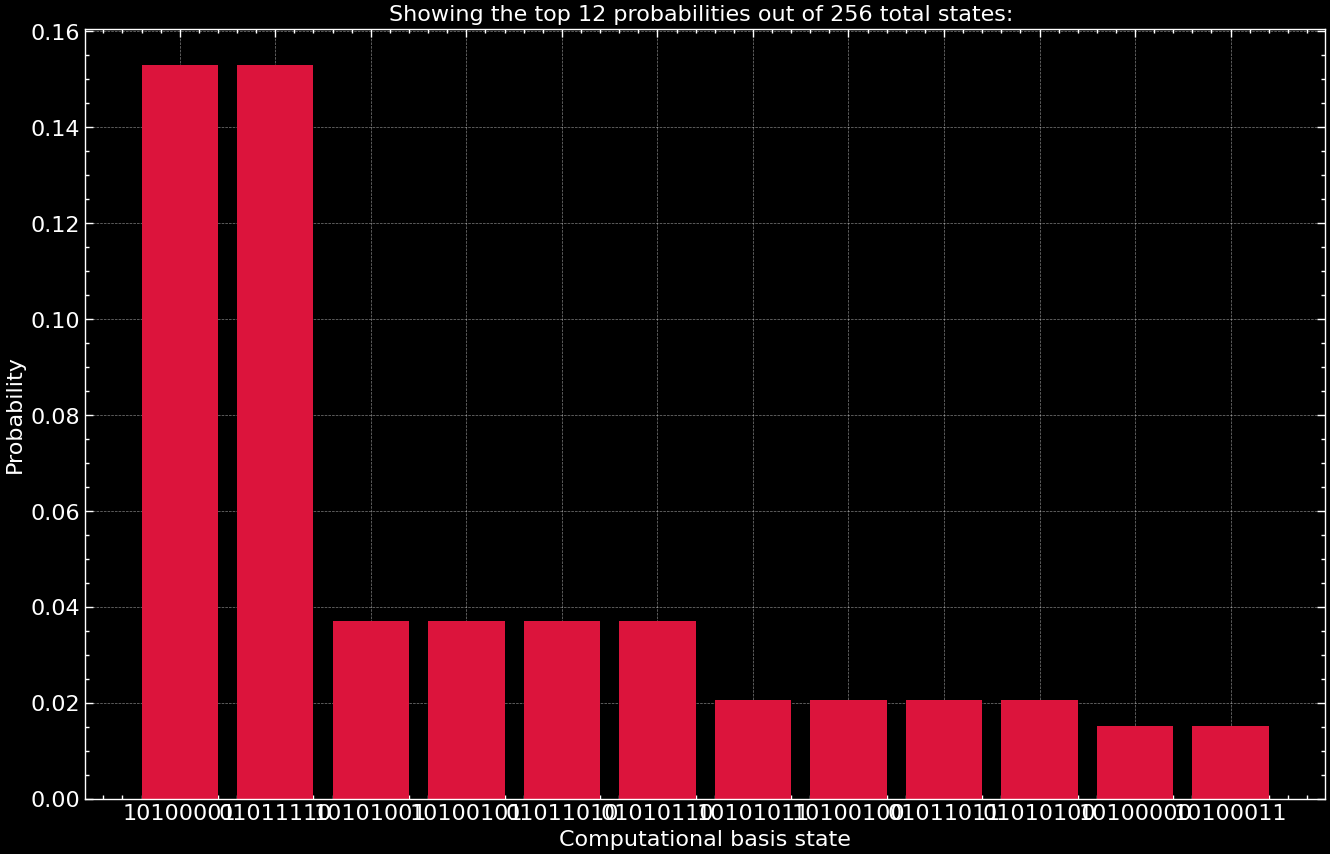

In [14]:
first_ev = eigenvectors[:, 0]
n_max = min(max(10, 2 ** n // 20), 30)
probabilities = np.abs(first_ev) ** 2

top_indices = np.argsort(probabilities)[-n_max:][::-1]

bitstrings = [format(i, f"0{n}b") for i in range(2 ** n)]
top_bitstrings = [bitstrings[i] for i in top_indices]
top_probabilities = probabilities[top_indices]

plt.figure(figsize = (16, 10))
plt.bar(top_bitstrings, top_probabilities, color = 'crimson')
plt.xlabel("Computational basis state")
plt.ylabel("Probability")
plt.title(f"Showing the top {n_max} probabilities out of {2 ** n} total states: ")
plt.show()

Now, QAOA. We need an Ansatz, simply because the Hamiltonian is not diagonal in the computational basis. All we need is a cost term (our ZZ interactions) and a mixer term (the transverse field). we can therefore do this for alternating layers of the cost and mixer unitaries, with variational parameters $\gamma$ and $\beta$ controlling the strength of each layer.

In [15]:
p = 4

ansatz_TFIM = QAOAAnsatz(

    cost_operator = H_TFIM,
    reps = p

)

ansatz_TFIM = ansatz_TFIM.decompose()

Since we're optimizing a quantum state for the actual physical Hamiltonian, I'll use an estimator-based objective:

In [16]:
estimator = StatevectorEstimator()
method = "COBYLA" # Choose from COBYLA, SPSA, L_BFGS_B, SLSQP, and others. COBYLA is a good default choice for small problems.
maxiter = 1000

def objective_TFIM(parameters):

    circuit = ansatz_TFIM.assign_parameters(parameters)
    job = estimator.run([(circuit, H_TFIM)])

    result = job.result()[0]
    return result.data.evs

In [17]:
initial_point = np.random.uniform(-np.pi, np.pi, ansatz_TFIM.num_parameters)

optimization_result = scipy.optimize.minimize(objective_TFIM, initial_point, method = method, options = {"maxiter": maxiter})
optimal_parameters_TFIM = optimization_result.x
ideal_qaoa_energy_TFIM = optimization_result.fun

print(f"Error in QAOA energy: {np.abs(ideal_qaoa_energy_TFIM - exact_ground_energy_TFIM) / np.abs(exact_ground_energy_TFIM) * 100:.2f}%")
print(f"with optimal parameters: {optimal_parameters_TFIM}")

c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:597: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\sparse\linalg\_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Error in QAOA energy: 4.96%
with optimal parameters: [ 1.85702755 -2.69569617 -0.41785762  3.17526804 -0.19102407  2.54867768
  0.0117699   3.96878094]


Sign in to your IBM Quantum account to access the QPUs. If you don't have an account, follow the instructions on my [introduction notebook](../01-introduction.ipynb) to create one. Once you have an account, you can use the `IBMQ` provider to access the QPUs!

In [18]:
service = QiskitRuntimeService(channel = 'ibm_cloud')
print(service.instances())

[{'crn': 'crn:v1:bluemix:public:quantum-computing:us-east:a/a23b3ad5cbea449e928534b2015d2561:4e27099a-3e5a-4eb0-a31f-1bbc4bb84f3d::', 'plan': 'open', 'name': 'qiskit-global-instance', 'tags': [], 'pricing_type': 'free'}]


In [19]:
backend = service.least_busy(simulator = False, operational = True)
backend.name, backend.num_qubits

('ibm_marrakesh', 156)

Measurement and the assignment of optimal parameters are the last steps before we can run on the QPU:

In [20]:
transpiled_TFIM = transpile(ansatz_TFIM, backend = backend, optimization_level = 3)
hardware_circuit = transpiled_TFIM.copy().assign_parameters(optimal_parameters_TFIM)
hardware_circuit.measure_all()

depth_overhead = (
    hardware_circuit.depth() / ansatz_TFIM.depth() - 1
) * 100

print(
    f"The transpiled circuit has depth {hardware_circuit.depth()} "
    f"compared to the original ansatz depth of {ansatz_TFIM.depth()}, "
    f"corresponding to a {depth_overhead:.2f}% depth overhead."
)

print(
    f"It contains {hardware_circuit.num_nonlocal_gates()} "
    f"nonlocal two-qubit gates."
)

The transpiled circuit has depth 331 compared to the original ansatz depth of 9, corresponding to a 3577.78% depth overhead.
It contains 143 nonlocal two-qubit gates.


In [22]:
transpiled_TFIM_p4 = transpile(
    hardware_circuit,
    backend=backend,
    optimization_level=3,
    layout_method="sabre",
    routing_method="sabre"
)

print(f"Transpiled depth: {transpiled_TFIM_p4.depth()}")
print(
    f"Nonlocal two-qubit gates: "
    f"{transpiled_TFIM_p4.num_nonlocal_gates()}"
)

Transpiled depth: 287
Nonlocal two-qubit gates: 143


This is the execution block. Review your depth and number of two-qubit gates before running on the QPU, as these two are the most influential sinks on your execution minutes. Use my templates if you want a safe, tested use of the QPU. Of course, you're always free to experiment, but be aware that the QPU is a shared resource, and your job may be queued for a while before execution!

The following is the execution block. You're using hardware from hereon, so be careful with your usage minutes. I'd recommend keeping it hardware-compatible to avoid hogging your quotas. My runs are recorded below, please do consider them to keep most of your minutes:

Run 1 (shallow): took minutes

Run 2 (moderately involved) took minutes:

Run 3 (deep): took mintes

In [ ]:
start_time = time()
result_TFIM = qaoa.compute_minimum_eigenvalue(operator = H_TFIM)
elapsed_time = time() - start_time

print(

    f"QAOA returned eigenvalue {result_TFIM.eigenvalue.real:.6f} "
    f"as compared to the exact eigenvalue {exact_ground_energy_TFIM:.6f} "
    f"with error of {np.abs(result_TFIM.eigenvalue.real - exact_ground_energy_TFIM) / np.abs(exact_ground_energy_TFIM) * 100:.2f}% "
    f"in {elapsed_time:.2f} seconds"

)         

In [51]:
hardware_runs = {

    "shallow": {

        "p": 1,
        "usage_minutes": None,
        "energy": None,
        "error": None

    },

    "medium": {

        "p": 3,
        "usage_minutes": None,
        "energy": None,
        "error": None

    },

    "deep": {

        "p": 5,
        "usage_minutes": None,
        "energy": None,
        "error": None

    }

}